# 모듈 5. RAG 평가

**목표**
1. **검색**이 정답 문단을 찾는지 숫자로 잰다 (Hit@k, MRR).
2. 평가셋의 **편향**을 찾아내고, 실제 사용자 질문에 가까운 조건에서 다시 잰다.
3. Claude의 **답변**을 SQL 참값·공시 원문·루브릭으로 채점한다.
4. 평가 결과로 시스템을 고치고, 고친 효과를 다시 잰다.

> "잘 되는 것 같다"는 느낌은 평가가 아닙니다. 실무에 쓰려면 **몇 %가 맞는지**, **어떤 질문에서 틀리는지**를 알아야 합니다.

In [1]:
import json

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from aifinance.config import DATA_DIR
from aifinance.plotting import setup_korean_font
from aifinance.rag_eval import (EVAL_DIR, check_citations, check_values, load_jsonl, retrieval_eval, summarize,
                                truth_values)

setup_korean_font()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

idx = duckdb.connect(str(DATA_DIR / "aifinance.duckdb"), read_only=True)        # 검색 색인 (표본)
full = duckdb.connect(str(DATA_DIR / "aifinance_full.duckdb"), read_only=True)  # SQL 참값 (전체 기간)

## 1. 검색 평가셋

`eval/retrieval_questions.jsonl`에 24문항이 있습니다. 질문은 공통 설명 20개와 특정 상품 4개입니다.

정답은 청크 번호가 아니라 **"정답 문단이라면 들어 있을 문구"**(`relevant_phrases`)로 적었습니다.
- 청크 크기나 임베딩 모델을 바꿔도 평가셋을 그대로 쓸 수 있습니다.
- 대신 문구가 너무 흔하면 아무 문단이나 정답이 됩니다. 그래서 전체 청크의 5% 미만에 나오는 문구를 골랐습니다.

질문마다 네 가지 표현이 있습니다.

| 필드 | 예 (r01) | 용도 |
|---|---|---|
| `query` | How does JPMorgan determine the estimated value of the notes? | 공시 용어를 아는 사람의 질문 |
| `query_ko` | JP모건은 노트의 추정가치를 어떻게 산정하나? | 한국어 질문 |
| `query_paraphrase` | What methodology does the bank use to come up with its own fair value…? | 공시 용어를 모르는 사람의 질문 |
| `query_rewritten` | estimated value of the notes determined by JPMS using internal pricing models… | 쉬운 말 질문을 **Claude가 공시 용어로 재작성** |

In [2]:
rq = load_jsonl(EVAL_DIR / "retrieval_questions.jsonl")
pd.DataFrame(rq)[["id", "query", "relevant_phrases", "cusip"]].head(8)

,id,query,relevant_phrases,cusip
0,r01,How does JPMorgan determine the estimated value of the notes?,[internal pricing models],NaN
1,r02,Why is the original issue price higher than the estimated value of the notes?,"[selling, structuring and hedging]",NaN
2,r03,What internal funding rate is used to value the notes?,[internal funding rate],NaN
3,r04,Whose credit risk does a noteholder bear?,"[credit risk of JPMorgan Chase & Co, credit risk of JPMorgan Financial]",NaN
4,r05,What happens to the contingent interest payment if the underlying closes below the interest barrier?,[no Contingent Interest Payment will be made],NaN
5,r06,Can the issuer redeem the notes early at its own election?,"[at our election, OPTIONAL EARLY REDEMPTION]",NaN
6,r07,How does the 6.0% per annum daily deduction affect the index level?,[daily deduction],NaN
7,r08,What potential conflicts of interest exist between JPMorgan and investors?,[POTENTIAL CONFLICTS],NaN


**지표**
- **Hit@k**: 상위 k개 안에 정답 문단이 하나라도 있는 질문의 비율
- **MRR**: 첫 정답 순위의 역수 평균. 1등이면 1, 2등이면 0.5, 없으면 0

In [3]:
base = pd.concat([retrieval_eval(idx, rq, m, lang) for lang in ["en", "ko"] for m in ["vector", "keyword", "hybrid"]])
summarize(base)

/Users/joocheol/Documents/GitHub/AIFinance/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


hit@1  hit@5    MRR
lang mode                        
en   hybrid   0.750  0.958  0.851
     keyword  0.792  0.833  0.832
     vector   0.667  0.958  0.786
ko   hybrid   0.042  0.083  0.061
     keyword  0.042  0.083  0.061
     vector   0.042  0.167  0.097

영어 질문에서는 세 방식 모두 Hit@5가 80~95%입니다. 한국어 질문은 거의 0입니다. 영어 전용 임베딩을 골랐으니 예상한 결과입니다.

## 2. 실패 분석 → 개선: 상품 지정 질문

질문별로 보면 **특정 상품을 묻는 질문(r21~r24)**에서 벡터·하이브리드가 무너집니다.
벡터 검색은 CUSIP 같은 식별자를 "뜻"으로 이해하지 못해, 다른 상품의 비슷한 문단을 가져옵니다.

**개선**: 검색어에 CUSIP이 있으면 그 상품의 청크로 범위를 자동으로 좁힌다 (`search(..., auto_cusip=True)`).

In [4]:
scoped = [q for q in rq if q["cusip"]]
before = pd.concat([retrieval_eval(idx, scoped, m, auto_cusip=False) for m in ["vector", "keyword", "hybrid"]]).assign(설정="개선 전")
after = pd.concat([retrieval_eval(idx, scoped, m, auto_cusip=True) for m in ["vector", "keyword", "hybrid"]]).assign(설정="개선 후")
pd.concat([before, after]).groupby(["설정", "mode"])[["hit@1", "hit@5", "rr"]].mean().rename(columns={"rr": "MRR"}).round(2)

hit@1  hit@5   MRR
설정   mode                       
개선 전 hybrid    0.25   0.50  0.37
     keyword   1.00   1.00  1.00
     vector    0.25   0.25  0.25
개선 후 hybrid    1.00   1.00  1.00
     keyword   1.00   1.00  1.00
     vector    0.75   1.00  0.88

## 3. 평가셋 편향: 질문에 정답 단어가 들어 있으면

원래 질문(`query`)은 공시 용어를 그대로 씁니다. 예를 들어 "Upside Leverage Factor"를 묻는 질문에 "upside leverage factor"가 들어 있습니다. 이러면 키워드 검색이 유리하고 점수가 부풀려집니다. 이것을 **라벨 누출(label leakage)**이라고 합니다.

실제 사용자는 공시 용어를 모릅니다. 같은 20문항을 쉬운 말로 바꾼 질문(`query_paraphrase`)으로 다시 재고,
그 쉬운 말 질문을 **Claude가 공시 용어로 재작성한 검색어**(`query_rewritten`)로도 잽니다.
재작성은 정답 문구를 보지 못한 별도의 Claude가 했습니다.

In [5]:
common = [q for q in rq if q.get("query_rewritten")]
variants = {"query": "① 공시 용어 질문", "query_paraphrase": "② 쉬운 말 질문", "query_rewritten": "③ Claude 재작성"}
rows = []
for field, label in variants.items():
    for m in ["vector", "keyword", "hybrid"]:
        r = retrieval_eval(idx, common, m, field=field)
        rows.append({"질문": label, "mode": m, "hit@5": r["hit@5"].mean(), "MRR": r["rr"].mean()})
bias = pd.DataFrame(rows)
bias.pivot(index="질문", columns="mode", values="MRR").round(3)

mode,hybrid,keyword,vector
질문,,,
① 공시 용어 질문,0.822,0.799,0.768
② 쉬운 말 질문,0.396,0.271,0.357
③ Claude 재작성,0.712,0.735,0.658


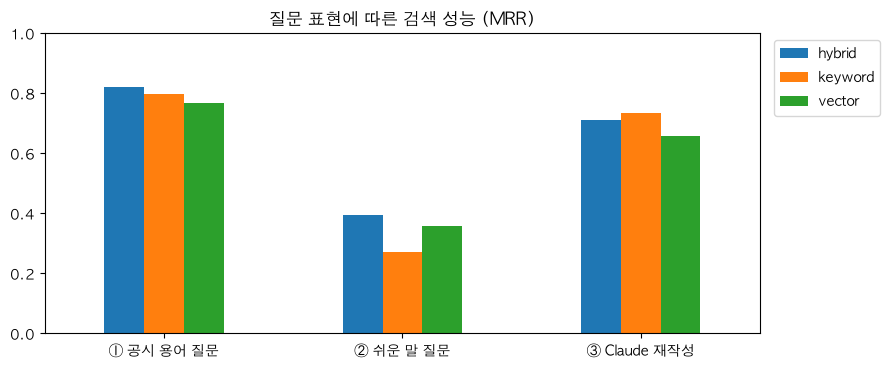

In [6]:
ax = bias.pivot(index="질문", columns="mode", values="MRR").plot(kind="bar", rot=0, figsize=(9, 3.8), title="질문 표현에 따른 검색 성능 (MRR)")
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

**읽는 법**
- ① → ②: 질문을 쉬운 말로 바꾸면 성능이 **절반 이하**로 떨어집니다. ①만 보고 "검색이 잘 된다"고 결론 내리면 안 됩니다.
- ② → ③: Claude가 검색어를 공시 용어로 바꾸면 **대부분 회복**됩니다. MCP 서버의 지침에 "사용자의 말을 그대로 옮기지 말고 공시 용어로 바꿔 검색하라"를 넣은 근거입니다.
- 키워드 검색은 표현 변화에 가장 취약하고, 하이브리드가 가장 안정적입니다.

## 4. 답변 평가

검색이 맞아도 답변이 틀릴 수 있습니다. 숫자를 잘못 옮기거나, 원문에 없는 내용을 지어낼 수 있습니다.
`eval/answer_questions.jsonl`의 11문항을 세 유형으로 나눠 채점합니다.

| 유형 | 문항 | 채점 방법 |
|---|---|---|
| `numeric` 집계 | 4 | `truth_sql`로 구한 참값과 `key_values` 자동 대조 |
| `lookup` 상품 조회 | 3 | 같음 |
| `explanation` 설명 | 4 | Claude 채점자가 루브릭으로 판정 (`prompts/answer_grading.md`) |
| (전체) | 11 | 인용문이 공시 원문에 **글자 그대로** 있는지 자동 확인 |

답변은 MCP 도구를 연결한 Claude가 `prompts/answer_generation.md` 지침대로 만들어 `eval/answers/`에 저장했습니다.
저장소에는 예시 답변이 들어 있습니다. 실습 5-A에서 직접 만들어 비교해 보세요.

In [7]:
aq = {q["id"]: q for q in load_jsonl(EVAL_DIR / "answer_questions.jsonl")}
answers = {p.stem: json.loads(p.read_text()) for p in sorted((EVAL_DIR / "answers").glob("*.json"))}
print(f"질문 {len(aq)}개, 답변 {len(answers)}개")
ex = answers.get("l1")
if ex:
    print(json.dumps(ex, ensure_ascii=False, indent=1)[:1500])

질문 11개, 답변 11개
{
 "id": "l1",
 "answer": "CUSIP 46661KGW2는 MerQube US Large-Cap Vol Advantage Index(MQUSLVA) 연계 Auto Callable Contingent Interest Notes(2029년 8월 24일 만기, 월지급·메모리 쿠폰)입니다. 확정 연 쿠폰율은 12.50%(월 1.04167%), 조기상환 기준(Call Value)은 최초가의 90%, 만기 배리어(Interest Barrier/Trigger Value)는 최초가의 65%입니다. 다만 자동 조기상환은 1~11번째 관찰일에는 적용되지 않고 12번째 관찰일부터 가능합니다. 판매 중 조건 변경: DB 기록상 예비본이 2건(2026-08-07, 2026-08-11) 있었고, 첫 예비본의 쿠폰율은 연 14.0%였으나 두 번째 예비본에서 12.5%로 낮아져 확정본도 12.5%로 정해졌습니다(품질 점검 Q12: 0.14 → 0.125 → 확정 0.125). 예비본 공시 원문 문구는 검색 색인에 없어 확인하지 못함. 추정가치는 $945.20(예비본 기준 $950.0)입니다.",
 "key_values": {
  "coupon_rate_pa": 0.125,
  "autocall_trigger_pct": 0.9,
  "barrier_pct": 0.65,
  "first_prelim_coupon_rate_pa": 0.14
 },
 "citations": [
  {
   "cusip": "46661KGW2",
   "url": "https://www.sec.gov/Archives/edgar/data/1665650/000191870426024634/form424b2.htm",
   "quote": "Contingent Interest Rate: 12.50% per annum, payable at a rate of 1.04167% per month"
  },
  {
   "cusip": "46661KGW2",
   "url": "htt

### 4-1. 숫자 채점

In [8]:
rows = []
for qid, q in aq.items():
    if q["type"] not in ("numeric", "lookup") or qid not in answers:
        continue
    truth = truth_values(full, q)
    ok = check_values(answers[qid], truth, q["tolerance"])
    for key, passed in ok.items():
        rows.append({"id": qid, "key": key, "참값": truth[key], "답변": answers[qid].get("key_values", {}).get(key), "일치": passed})
values = pd.DataFrame(rows)
print(f"숫자 정확도: {values['일치'].mean():.0%} ({values['일치'].sum()}/{len(values)})")
values

숫자 정확도: 100% (15/15)


,id,key,참값,답변,일치
0,n1,top_family,autocall_contingent_coupon,autocall_contingent_coupon,True
1,n1,count,914,914,True
2,n2,avg_coupon_pa,0.130454,0.130454,True
3,n3,coupon_diff_pa,-0.028828,-0.028968,True
4,n4,lowest_family,autocall_call_premium,autocall_call_premium,True
5,n4,avg_estimated_value,941.525044,941.517688,True
6,l1,coupon_rate_pa,0.125,0.125,True
7,l1,autocall_trigger_pct,0.9,0.9,True
8,l1,barrier_pct,0.65,0.65,True
9,l1,first_prelim_coupon_rate_pa,0.14,0.14,True


### 4-2. 인용 검증

인용된 링크가 DB에 있는 공시인지, 인용문이 그 공시 원문에 그대로 있는지 확인합니다. LLM이 그럴듯한 인용을 **지어내는지** 잡아내는 가장 간단한 검사입니다.

In [9]:
cites = pd.concat([check_citations(a, full).assign(id=qid) for qid, a in answers.items()], ignore_index=True)
print(f"인용 {len(cites)}개 | 링크 확인 {cites.url_known.mean():.0%} | 원문 일치 {cites.quote_found.fillna(False).mean():.0%}")
cites[~cites.quote_found.fillna(False).astype(bool)]

인용 32개 | 링크 확인 100% | 원문 일치 100%


,url_known,quote,quote_found,id


### 4-3. 설명 채점 (Claude 채점자)

설명형 답변은 정답이 하나가 아닙니다. 그래서 **루브릭**(꼭 들어가야 할 내용 목록)을 미리 정하고, 답변을 만든 대화와 **다른 대화의 Claude**가 채점합니다.
채점자는 근거 없는 사실 주장도 찾아냅니다.

In [10]:
judgments = {p.stem: json.loads(p.read_text()) for p in sorted((EVAL_DIR / "judgments").glob("*.json"))}
jrows = []
for qid, j in judgments.items():
    jrows.append({"id": qid, "질문": aq[qid]["question"][:50], "루브릭 점수": j["score"],
                  "충족": f"{sum(r['met'] for r in j['rubric'])}/{len(j['rubric'])}",
                  "근거 없는 주장": len(j.get("unsupported_claims", [])), "총평": j.get("comment", "")})
pd.DataFrame(jrows)

,id,질문,루브릭 점수,충족,근거 없는 주장,총평
0,e1,"JP Morgan 구조화 노트의 추정가치가 발행가($1,000)보다 낮은 이유를 공시에 근",0.75,3/4,0,"(루브릭 4번은 1차 채점 후 공시 원문 표현에 맞게 수정되었으며, 수정된 루브릭으로 재채점함) 발행가에 포함된 비용(판매수수료, 구조화·헤지 비용, 계열사 예상이익, 제3자 플랫폼 수수료)은 공시 문구와 정..."
1,e2,워스트오브(least performing) 구조의 투자 위험을 공시에 근거해 설명해줘.,1.00,4/4,1,"워스트오브 구조의 핵심 위험(개별 성과 연동, 상쇄 불가, 낮은 상관관계, 하나만 배리어 하회해도 손실)을 공시 문구에 맞게 모두 설명했으나, 마지막 쿠폰 비교는 주식 그룹에만 성립하는 결과를 '같은 자산 유..."
2,e3,MerQube Vol Advantage 지수의 연 6% 일일 차감이 투자자 수익에 미치는,1.00,4/4,0,"6% 일일 차감의 효과(상승 상쇄, 하락 확대, 횡보 시 하락, 차감 없는 지수 대비 열위, 조건 개선이 차감을 상쇄한다는 보장 없음)를 공시 문구대로 정확히 설명했고, QQQ 명목 금융비용 추가 차감과 MQ..."
3,e4,발행사가 재량으로 조기상환할 수 있는(issuer callable) 조건부 쿠폰 상품에서,1.00,4/4,0,"조기상환 위험(만기 단축 약 3개월~1년, 이후 쿠폰 없음, 재투자 위험, 수수료 미환급), 쿠폰 미보장, 만기 원금 손실, 중도매도 손실을 공시 문구에 맞게 설명했고 상품군 통계(240개, 10.70%, 2..."


In [11]:
# 충족하지 못한 루브릭과 근거 없는 주장
for qid, j in judgments.items():
    missed = [r["item"] for r in j["rubric"] if not r["met"]]
    claims = j.get("unsupported_claims", [])
    if missed or claims:
        print(f"[{qid}]")
        for m in missed:
            print("  ✗ 루브릭 미충족:", m)
        for c in claims:
            print("  ⚠ 근거 없음:", c["claim"][:100], "→", c["why"][:100])

[e1]
  ✗ 루브릭 미충족: 추정가치 산정에 JPM 내부 조달금리(internal funding rate)를 쓰며, 이 금리가 시장 금리와 다를 수 있고 노트 조건·유통가격에 불리하게 작용할 수 있음
[e2]
  ⚠ 근거 없음: 이런 추가 위험 때문에 같은 자산 유형끼리 보면 워스트오브의 쿠폰이 더 높게 책정됩니다(예: 주식 3개 워스트오브 오토콜 평균 18.78% vs 단일 주식 14.45%, query → 답변이 제시한 SQL을 재실행한 결과 주식 그룹(18.78% vs 14.45%)은 맞지만, 같은 쿼리에서 지수 그룹은 3개 워스트오브 8.82% vs 단일 지수 13.38%, ET


## 5. 스코어카드

In [12]:
hyb = summarize(base).loc[("en", "hybrid")]
bias_h = bias[bias["mode"] == "hybrid"].set_index("질문")["MRR"]
card = pd.DataFrame([
    ("검색", "영어 질문 Hit@5 (하이브리드)", f"{hyb['hit@5']:.0%}"),
    ("검색", "쉬운 말 질문 MRR → Claude 재작성 후", f"{bias_h['② 쉬운 말 질문']:.2f} → {bias_h['③ Claude 재작성']:.2f}"),
    ("검색", "상품 지정 질문 MRR (CUSIP 자동 범위)", f"{after[after['mode'] == 'hybrid'].rr.mean():.2f}"),
    ("답변", "숫자·조회 정확도", f"{values['일치'].mean():.0%}"),
    ("답변", "인용문 원문 일치율", f"{cites.quote_found.fillna(False).mean():.0%}"),
    ("답변", "설명 루브릭 평균 점수", f"{pd.DataFrame(jrows)['루브릭 점수'].mean():.0%}"),
    ("답변", "근거 없는 주장 (건)", str(int(pd.DataFrame(jrows)['근거 없는 주장'].sum()))),
], columns=["영역", "지표", "값"])
card

,영역,지표,값
0,검색,영어 질문 Hit@5 (하이브리드),96%
1,검색,쉬운 말 질문 MRR → Claude 재작성 후,0.40 → 0.71
2,검색,상품 지정 질문 MRR (CUSIP 자동 범위),1.00
3,답변,숫자·조회 정확도,100%
4,답변,인용문 원문 일치율,100%
5,답변,설명 루브릭 평균 점수,94%
6,답변,근거 없는 주장 (건),1


## 6. 평가가 찾아낸 결함과 조치

평가의 진짜 가치는 점수가 아니라 **무엇을 고쳐야 하는지 알려 주는 것**입니다. 이번 모듈에서 평가가 찾아낸 결함은 검색, 추출기, 답변, 그리고 **평가셋 자체**에 걸쳐 있습니다.

| 찾은 곳 | 결함 | 누가 찾았나 | 조치 |
|---|---|---|---|
| 검색 | 벡터 검색이 CUSIP을 무시하고 다른 상품 문단을 가져옴 | 검색 평가 (r21~r24) | 검색어에 CUSIP이 있으면 자동으로 범위 지정 |
| 검색 | 쉬운 말 질문에서 성능 절반 이하 | 표현 바꾼 평가셋 | MCP 지침에 "공시 용어로 바꿔 검색" 추가 |
| 추출기 | Wells Fargo 형식의 **"Lowest Performing"**을 몰라 워스트오브 47개를 단일 기초자산으로 분류 | 답변 Claude (기초자산 수와 basket_type이 모순인 행 발견) | 패턴 추가 → n3 참값이 −3.34%p에서 −2.88%p로 바뀜 |
| 추출기 | **조건부 버퍼**(Contingent Buffer)를 일반 버퍼로 분류. 실제로는 넘으면 하락분 전체 손실 = 배리어 | 답변 Claude (l3) | (1 − 버퍼) 배리어로 모델링, 상품군도 leveraged_barrier로 |
| 답변 | "같은 자산 유형끼리는 워스트오브 쿠폰이 더 높다"는 과잉 일반화. 개별 주식에서만 성립 | Claude 채점자 (SQL 재실행) | 답변 지침에 "일반화는 계산한 숫자로 뒷받침" 강조 |
| **평가셋** | e1 루브릭이 공시에 없는 방향("부채 가치를 낮춘다")을 단정 | Claude 채점자 | 루브릭을 공시 표현("다를 수 있고 불리하게 작용할 수 있음")으로 수정 |

> 마지막 줄이 특히 중요합니다. **평가셋도 사람이 만든 데이터이므로 틀릴 수 있습니다.** 채점 결과가 이상하면 답변만이 아니라 정답과 루브릭도 원문으로 다시 확인해야 합니다.

## 🤖 Claude 실습 5

**5-A. 내 Claude로 답변 만들어 비교하기**
> `prompts/answer_generation.md` 지침대로 `eval/answer_questions.jsonl`의 질문 3개(n3, l1, e2)에 답하고 `scratch/answers/<id>.json`으로 저장해줘. 그다음 `eval/answers/`의 예시 답변과 비교해 숫자·인용·설명에서 무엇이 다른지 표로 정리해줘.

**5-B. 평가셋 키우기**
> 실무자가 실제로 물을 법한 쉬운 말 질문 10개를 새로 만들고, 각 질문의 정답 문구(`relevant_phrases`)를 공시 원문에서 찾아 `eval/retrieval_questions.jsonl` 형식으로 `scratch/`에 저장해줘. 정답 문구가 전체 청크의 5%를 넘으면 더 구체적인 문구로 바꿔. 그다음 노트북 05의 측정을 새 질문으로 다시 돌려줘.

**5-C. 검색 설정 튜닝**
> 청크 크기(800·1200·2000자)와 공통 문구 기준(3%·5%·10%)을 바꿔 색인을 다시 만들고(별도 DB 파일에), 쉬운 말 질문(`query_paraphrase`)과 재작성 질문(`query_rewritten`) 기준 MRR을 비교해줘. 색인 시간도 함께 표로 보여주고 추천 설정을 제시해줘.

**5-D. 채점자는 믿을 만한가**
> `prompts/answer_grading.md`로 설명형 답변 4개를 다시 채점해줘(`eval/judgments/`는 보지 말고). 기존 채점과 루브릭 항목별로 일치율을 계산하고, 판정이 갈린 항목은 공시 원문을 근거로 어느 쪽이 맞는지 판단해줘.

---
**다음 모듈**: 모듈 6에서는 이 시스템으로 **JPM 상품군을 본격적으로 분석**합니다. 상품군·기초자산·조건의 분포, 추정가치로 본 발행 마진, 시기별 추세, 판매 채널(플랫폼)이 주제입니다.